## 1. Importar bibiotecas:

In [1]:
import geopandas as gpd
import momepy
import numpy as np

## 2. Importar o geopkacge e ver a camada:


In [2]:
buildings = gpd.read_file("edificios_porto.gpkg")
buildings.head()

,geometry
0,"MULTIPOLYGON (((-8.56961 41.16358, -8.56961 41..."
1,"MULTIPOLYGON (((-8.56975 41.16342, -8.56975 41..."
2,"MULTIPOLYGON (((-8.5696 41.16319, -8.56961 41...."
3,"MULTIPOLYGON (((-8.58038 41.17137, -8.5803 41...."
4,"MULTIPOLYGON (((-8.56977 41.16387, -8.56976 41..."


## 3. Confirmar os dados

### 3.1 Quantos edifícios e que colunas

In [3]:
buildings.shape

(43465, 1)

### 3.2 Sistema de coordenadas (CRS)

As medidas de área e comprimento só fazem sentido se forem em metros. 
Paraisso o CRS tem de ser projetado (ex.: EPSG:3763, PT-TM06, em Portugal). Se `is_projected` der `False`, as coordenadas estão em graus e é preciso reprojetar:

In [4]:
print(buildings.crs)
print(buildings.crs.is_projected)

EPSG:4326
False


Como os buildings nao estao projetados, temos de projeta-los para o crs correto:

In [5]:
buildings = buildings.to_crs(3763)

### 3.3 Tipo de geometria

Devem ser "Polygon" ou "MultiPolygon". Se aparecerem linhas ou pontos, é porque não são edifícios:

In [6]:
buildings.geom_type.value_counts()

MultiPolygon    43465
Name: count, dtype: int64

Neste caso, está tudo bem. Sao 43 465 multipoligonos de edificios

### 3.4 Geometrias vazias, em falta ou inválidas

O caodigo de baixo permite perceber as gemetricas em falta:

In [7]:
print("em falta:", buildings.geometry.isna().sum())


em falta: 0


Geometrias vazias:

In [8]:
print("vazias:", buildings.geometry.is_empty.sum())


vazias: 0


E geometrias inválidas:

In [9]:
print("inválidas:", (~buildings.geometry.is_valid).sum())

inválidas: 0


### 3.5 Mapa

Ver se os edifícios aparecem onde se espera e se não há nada estranho (edifícios soltos longe, buracos na cobertura). Podes ajustar o tamanho do mapa alterando os numeros de (figsize=(x, x):

<Axes: >

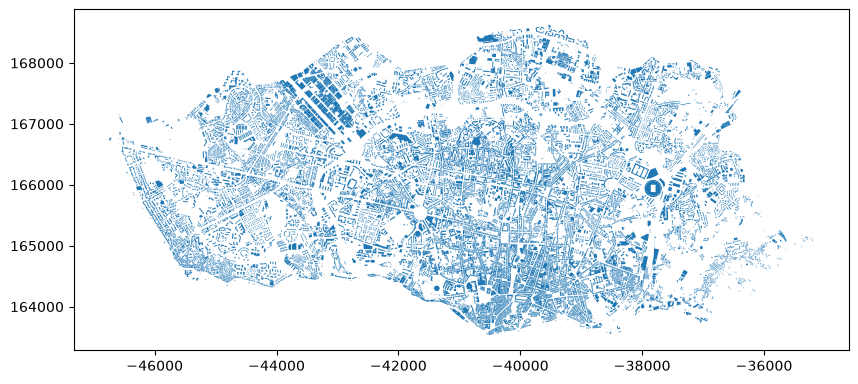

In [10]:
buildings.plot(figsize=(10, 10))

## 4. Limpeza

1. Retirar geometrias em falta ou vazias.
2. Corrigir as inválidas com "make_valid()".
3. Ficar só com polígonos.

No fim, confirmamos que já não há problemas.

In [11]:
buildings = buildings[buildings.geometry.notna()]
buildings = buildings[~buildings.geometry.is_empty]
buildings.geometry = buildings.geometry.make_valid()
buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])]
buildings = buildings.reset_index(drop=True)

print(buildings.shape)
print("inválidas:", (~buildings.geometry.is_valid).sum())

(43465, 1)
inválidas: 0


## 5. Medidas

### 5.1 Área (m2) e perímetro (m)

In [12]:
buildings["area"] = buildings.area
buildings["perimetro"] = buildings.length

### 5.2 Comprimento e largura (m)

Para obtermos o comprimento e a largura, o processo normal é desenharmos à volta de cada edifício o menor retângulo que o contém, podendo rodar (retângulo mínimo rodado). O lado maior é o comprimento, o menor é a largura:

In [14]:
retangulo = buildings.geometry.minimum_rotated_rectangle()

A = retangulo.area
s = retangulo.length / 2
raiz = np.sqrt(np.clip(s**2 - 4 * A, 0, None))

buildings["comprimento"] = (s + raiz) / 2
buildings["largura"] = (s - raiz) / 2

### 5.3 Alongamento

Largura a dividir pelo comprimento. Perto de 1: forma quadrada; perto de 0: forma comprida e estreita.

In [15]:
buildings["alongamento"] = buildings["largura"] / buildings["comprimento"]

### 5.4 Compacidade circular

Área do edifício a dividir pela área do menor círculo que o contém. Perto de 1: forma compacta; perto de 0: forma recortada ou esticada.

In [16]:
buildings["compacidade"] = momepy.circular_compactness(buildings)

### 5.5 Orientação (graus, 0–45)

Desvio do eixo do edifício em relação aos pontos cardeais. 0: alinhado norte-sul/este-oeste; 45: em diagonal.

In [17]:
buildings["orientacao"] = momepy.orientation(buildings)

## 6. Verificar os resultados

### 6.1 Resumo em tabela

Ver os mínimos e os máximos. Podemos verificar se existem áreas com poucos m2 ou larguras quase nulas. Podem indicar polígonos que não são propriamente edifícios (anexos, garagens, etc):

In [18]:
medidas = ["area", "perimetro", "comprimento", "largura", "alongamento", "compacidade", "orientacao"]
buildings[medidas].describe()

,area,perimetro,comprimento,largura,alongamento,compacidade,orientacao
count,43465.000000,43465.000000,43465.000000,43465.000000,43465.000000,43465.000000,43465.000000
mean,229.012502,59.052723,19.667560,9.900958,0.562600,0.462838,20.514238
std,570.022351,54.533593,17.169950,8.418987,0.222064,0.124403,13.004753
min,0.259152,1.816140,0.574452,0.572142,0.014061,0.017732,0.000346
25%,58.425722,33.286152,10.663293,5.562798,0.382661,0.375766,9.771834
50%,104.505454,45.905477,15.652079,7.394284,0.544102,0.477958,19.299908
75%,206.839634,64.505311,21.543938,11.739288,0.738406,0.564117,31.400035
max,36287.514768,1887.944803,401.660705,282.194627,0.999994,0.980848,44.998712


### 6.2 Histograma da área

Permite, por exemplo, ver a distribuiçao das áreas dos edificios de toda a área:

<Axes: ylabel='Frequency'>

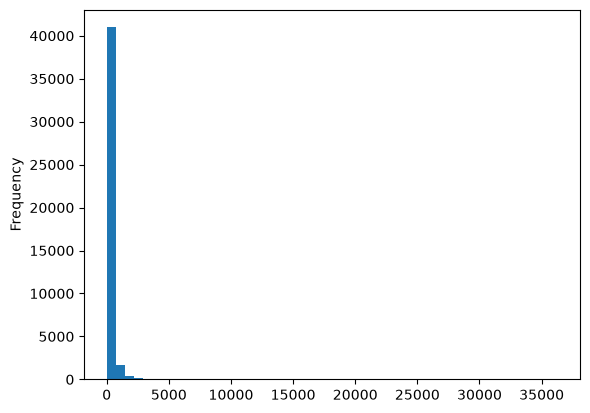

In [19]:
buildings["area"].plot.hist(bins=50)

### 6.3 Mapas

Ver onde estão os valores. `scheme="quantiles"` divide os edifícios em 5 grupos com o mesmo número de edifícios (é identico ao Qgis):

<Axes: >

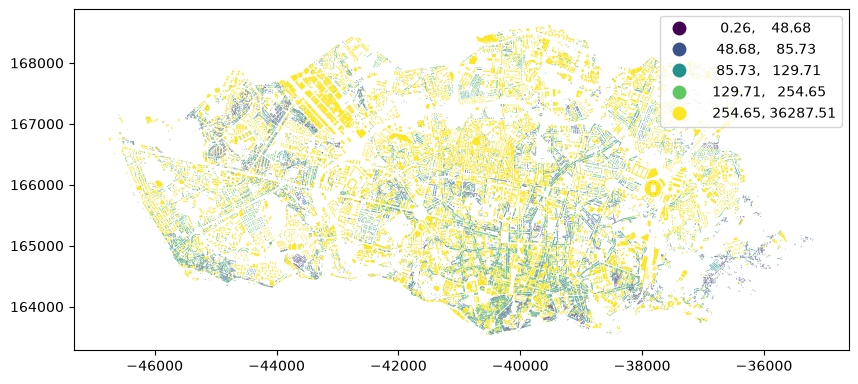

In [20]:
buildings.plot("area", scheme="quantiles", k=5, legend=True, figsize=(10, 10))

A vantagem do mapa explore é que permite ver os valores de cada edificio (se passar o mouse por cima do edificio aparecem os valores das 7 variaveis):

No entanto, o mapa explore abaixo, apenas as cores da distribuição da variavel "largura". Podes trocar "largura" por outra variavel (comprimento, area, alongamento, etc):

In [ ]:
buildings.explore("largura", scheme="quantiles", k=5, tiles="OpenStreetMap HOT")

## 7. Guardar

Grava os edifícios com as novas colunas num novo GeoPackage.

In [23]:
buildings.to_file("edificios_morfometria.gpkg", layer="edificios")